# 3. Модели

Обучаем три модели, сравниваем, калибруем лучшую и сохраняем её. Функции лежат в `src/models.py`.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))   # чтобы работал импорт из папки src

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay

from src import config, data, features, models

In [2]:
clean = data.clean(data.load_raw())
df = features.prepare_for_model(clean)   # категории -> текст
len(features.FEATURES)

36

## Разбиение по пациентам

У многих пациентов несколько визитов. Если один визит попадёт в обучение, а другой в проверку, модель «узнает» человека и оценка будет завышена. Поэтому в test уходит 20% пациентов целиком.

In [3]:
train, test = models.split_by_patient(df)
print("train:", len(train), "строк;  test:", len(test), "строк")
print("Общих пациентов:", len(set(train["patient_nbr"]) & set(test["patient_nbr"])))

train: 79567 строк;  test: 19773 строк
Общих пациентов: 0


In [4]:
X_train, y_train, groups = train[features.FEATURES], train[features.TARGET], train[features.GROUP]
X_test, y_test = test[features.FEATURES], test[features.TARGET]

## Pipeline

Pipeline — цепочка «подготовка признаков → модель». Подготовка учится только на обучающей части, поэтому данные test в неё не попадают.

- числа: пропуск → медиана, затем единый масштаб;
- категории: one-hot — каждая категория становится столбцом из 0 и 1.

In [5]:
candidates = models.get_models()
list(candidates)

['Dummy (baseline)', 'Logistic Regression', 'LightGBM']

## Метрики

| Метрика | Что показывает |
|---|---|
| ROC-AUC | насколько хорошо модель упорядочивает пациентов по риску; 0,5 — случайно |
| PR-AUC | то же с упором на редкий класс; у случайной модели равен доле возвратов (0,11) |
| Brier | ошибка самих вероятностей; меньше — лучше |
| precision | из названных рискованными сколько реально вернулись |
| recall | из реально вернувшихся скольких модель нашла |
| F1 | баланс precision и recall |

## Dummy — точка отсчёта

Dummy всем пациентам выдаёт среднюю долю возвратов. С ним сравниваются остальные модели.

In [6]:
pipeline, grid, n_iter = candidates[models.DUMMY]
dummy, params, seconds = models.fit_model(pipeline, grid, n_iter, X_train, y_train, groups)

In [7]:
rows = [models.evaluate(models.DUMMY, dummy, X_test, y_test, threshold=0.5) | {"train_sec": seconds}]
rows[0]

{'model': 'Dummy (baseline)',
 'roc_auc': 0.5,
 'pr_auc': 0.1135,
 'brier': 0.1006,
 'threshold': 0.5,
 'precision': 0.0,
 'recall': 0.0,
 'f1': 0.0,
 'size_mb': 0.015,
 'train_sec': 2.0}

## Logistic Regression

Линейная модель: складывает признаки с весами и превращает сумму в вероятность. `class_weight="balanced"` увеличивает вес редкого класса.

Параметр `C` подбираем кросс-валидацией: train делится на 4 части без общих пациентов, модель по очереди проверяется на каждой.

In [8]:
pipeline, grid, n_iter = candidates[models.LOGREG]
logreg, params, seconds = models.fit_model(pipeline, grid, n_iter, X_train, y_train, groups)
print(params, "—", seconds, "с")

{'clf__C': 0.1} — 66.2 с


**Порог.** Вероятность выше порога означает «высокий риск». Возвратов мало, поэтому берём не 0,5, а порог с максимальным F1. Он подбирается только на train.

In [9]:
threshold = models.choose_threshold(logreg, X_train, y_train, groups)
rows.append(models.evaluate(models.LOGREG, logreg, X_test, y_test, threshold) | {"train_sec": seconds})
rows[-1]

{'model': 'Logistic Regression',
 'roc_auc': 0.6728,
 'pr_auc': 0.2262,
 'brier': 0.2242,
 'threshold': 0.5316,
 'precision': 0.2012,
 'recall': 0.471,
 'f1': 0.2819,
 'size_mb': 0.017,
 'train_sec': 66.2}

## LightGBM

Градиентный бустинг: много небольших деревьев решений, каждое исправляет ошибки предыдущих. Ловит нелинейные связи. `is_unbalance=True` учитывает редкий класс.

In [10]:
pipeline, grid, n_iter = candidates[models.LGBM]
lgbm, params, seconds = models.fit_model(pipeline, grid, n_iter, X_train, y_train, groups)
print(params, "—", seconds, "с")

{'clf__subsample_freq': 1, 'clf__subsample': 1.0, 'clf__reg_lambda': 1, 'clf__num_leaves': 63, 'clf__n_estimators': 400, 'clf__min_child_samples': 50, 'clf__learning_rate': 0.02, 'clf__colsample_bytree': 0.6} — 315.0 с


In [11]:
threshold = models.choose_threshold(lgbm, X_train, y_train, groups)
rows.append(models.evaluate(models.LGBM, lgbm, X_test, y_test, threshold) | {"train_sec": seconds})
rows[-1]

{'model': 'LightGBM',
 'roc_auc': 0.6806,
 'pr_auc': 0.2479,
 'brier': 0.205,
 'threshold': 0.5594,
 'precision': 0.2293,
 'recall': 0.4064,
 'f1': 0.2932,
 'size_mb': 2.705,
 'train_sec': 315.0}

## Калибровка

Из-за учёта дисбаланса модель завышает вероятности. Калибровка учит поправку «что модель сказала → что было на самом деле» на 25% пациентов train, которых модель не видела.

In [12]:
calibrated, threshold = models.calibrate(lgbm, X_train, y_train, groups)
name = models.LGBM + " + isotonic calibration"
rows.append(models.evaluate(name, calibrated, X_test, y_test, threshold) | {"train_sec": 0})

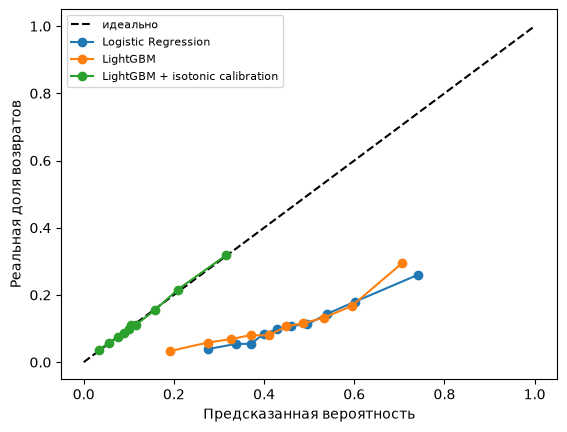

In [13]:
plt.plot([0, 1], [0, 1], "k--", label="идеально")
for label, model in [(models.LOGREG, logreg), (models.LGBM, lgbm), (name, calibrated)]:
    real, predicted = calibration_curve(y_test, model.predict_proba(X_test)[:, 1], n_bins=10, strategy="quantile")
    plt.plot(predicted, real, marker="o", label=label)
plt.xlabel("Предсказанная вероятность"); plt.ylabel("Реальная доля возвратов"); plt.legend(fontsize=8);

До калибровки линии лежат ниже диагонали: модель говорит «50%», а возвращаются около 12%. После калибровки линия ложится на диагональ.

## Сравнение моделей

In [14]:
table = pd.DataFrame(rows)
table

,model,roc_auc,pr_auc,brier,threshold,precision,recall,f1,size_mb,train_sec
0,Dummy (baseline),0.5000,0.1135,0.1006,0.5000,0.0000,0.0000,0.0000,0.015,2.0
1,Logistic Regression,0.6728,0.2262,0.2242,0.5316,0.2012,0.4710,0.2819,0.017,66.2
2,LightGBM,0.6806,0.2479,0.2050,0.5594,0.2293,0.4064,0.2932,2.705,315.0
3,LightGBM + isotonic calibration,0.6785,0.2306,0.0950,0.1500,0.2240,0.4430,0.2975,2.701,0.0


Обе модели лучше Dummy. LightGBM немного лучше логистической регрессии. Калибровка уменьшила Brier вдвое.

## Матрица ошибок

Строки — что было на самом деле, столбцы — что сказала модель.

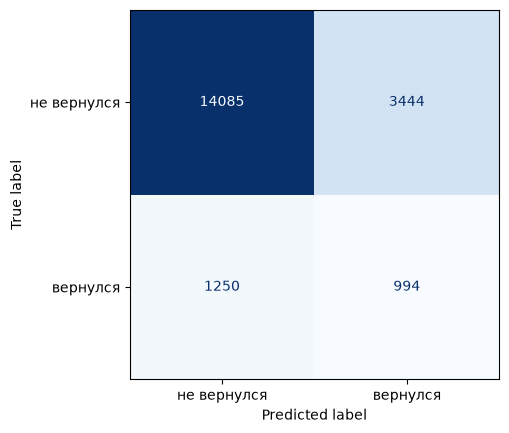

In [15]:
pred = calibrated.predict_proba(X_test)[:, 1] >= threshold
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["не вернулся", "вернулся"], cmap="Blues", colorbar=False);

Найдено 994 вернувшихся, пропущено 1 250, ложных тревог 3 444.

## Важность признаков

Permutation importance: перемешиваем значения одного признака и смотрим, насколько упал PR-AUC. Чем сильнее упал — тем важнее признак.

In [16]:
sample = X_test.sample(n=6000, random_state=config.RANDOM_STATE)
result = permutation_importance(calibrated, sample, y_test.loc[sample.index], scoring="average_precision",
                                n_repeats=5, random_state=config.RANDOM_STATE)

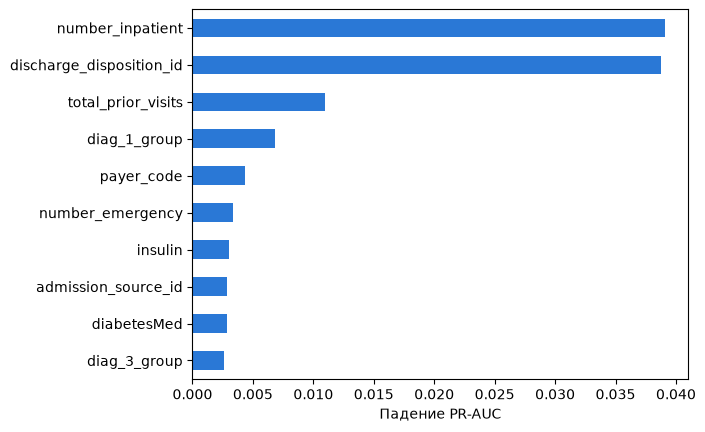

In [17]:
importance = pd.Series(result.importances_mean, index=sample.columns).sort_values()
importance.tail(10).plot.barh(color="#2a78d6")
plt.xlabel("Падение PR-AUC");

Важнее всего число прошлых госпитализаций и тип выписки — как и в EDA.

## Анализ ошибок

Сравниваем вернувшихся пациентов, которых модель пропустила и которых нашла.

In [18]:
returned = test[y_test == 1].assign(found=pred[y_test == 1])
columns = ["number_inpatient", "number_emergency", "time_in_hospital", "num_medications", "age_num"]
returned.groupby("found")[columns].mean().round(2).rename(index={False: "пропущены", True: "найдены"})

,number_inpatient,number_emergency,time_in_hospital,num_medications,age_num
found,,,,,
пропущены,0.31,0.14,4.48,16.39,67.10
найдены,2.47,0.63,4.95,17.51,64.99


Модель пропускает пациентов без прошлых госпитализаций. По остальным признакам они не отличаются от найденных.

## Сохранение

Лучшая модель сохраняется в `models/best_model.joblib`, таблица сравнения — в `models/metrics.parquet`.

In [19]:
table["best_params"] = ""
models.save_model(calibrated, threshold, name, table)
print("Сохранено:", config.MODEL_PATH.name, "и", config.METRICS_PATH.name)

Сохранено: best_model.joblib и metrics.parquet


## Прогноз для одного пациента

In [20]:
patient = {"age_num": 75, "time_in_hospital": 8, "num_medications": 25, "number_inpatient": 4,
           "number_emergency": 2, "total_prior_visits": 6, "number_diagnoses": 9}
models.predict_patient(patient)

{'probability': 0.3045977011494253,
 'high_risk': True,
 'threshold': 0.15,
 'model': 'LightGBM + isotonic calibration'}

## Выводы

- ROC-AUC 0,68 и PR-AUC 0,25 против 0,50 и 0,11 у Dummy.
- Итоговая модель находит 44% вернувшихся пациентов.
- Калибровка снизила ошибку вероятностей с 0,205 до 0,095.
- Главные признаки — история госпитализаций и тип выписки.